## Final Project Planning Lab: SUPPORT2

**Dataset:** SUPPORT2 (Study to Understand Prognoses and Preferences for Outcomes and Risks of Treatments)

**Source:** UCI Machine Learning Repository

https://archive.ics.uci.edu/dataset/880/support2

**Proposed Prediction Problem:** Can demographic, clinical, physiologic, and disease-related characteristics be used to predict in-hospital mortality among seriously ill hospitalized patients?

**Target Variable:** `hospdead`
- `0` = Patient did not die in the hospital
- `1` = Patient died in the hospital

## Dataset Selection

The SUPPORT2 dataset contains records from 9,105 seriously ill hospitalized patients treated at five medical centers in the United States. The dataset includes 42 features containing demographic, clinical, physiologic, and disease severity information.

This dataset meets the requirements for the final project because it contains more than 300 observations, more than 10 predictor variables, and supports a binary classification problem using in-hospital mortality (`hospdead`) as the target variable.

I selected this dataset because I currently work in hospice and am particularly interested in serious illness, prognosis, palliative care, and end-of-life decision-making. The SUPPORT study is relevant to these interests because it examined outcomes and care among seriously ill hospitalized patients. From a health data science perspective, the dataset also provides an opportunity to explore how patient-level clinical information can be used to predict important health outcomes.

## Dataset Exploration

### Importing Dataset

In [1]:
# Installing UCI ML Repo package
!pip install ucimlrepo -q

In [2]:
# Importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

In [3]:
# Import SUPPORT2 dataset from UCI ML Repo
support2 = fetch_ucirepo(id=880)

# Separate predictor features and target variables
x = support2.data.features
y = support2.data.targets

In [4]:
# Verifying import
print("Predictor dataset shape:", x.shape)
print("Target dataset shape:", y.shape)

display(x.head())
display(y.head())

Predictor dataset shape: (9105, 42)
Target dataset shape: (9105, 3)


,age,sex,dzgroup,dzclass,num.co,edu,income,scoma,charges,totcst,...,bili,crea,sod,ph,glucose,bun,urine,adlp,adls,adlsc
0,62.84998,male,Lung Cancer,Cancer,0,11.0,$11-$25k,0.0,9715.0,NaN,...,0.199982,1.199951,141.0,7.459961,NaN,NaN,NaN,7.0,7.0,7.0
1,60.33899,female,Cirrhosis,COPD/CHF/Cirrhosis,2,12.0,$11-$25k,44.0,34496.0,NaN,...,NaN,5.500000,132.0,7.250000,NaN,NaN,NaN,NaN,1.0,1.0
2,52.74698,female,Cirrhosis,COPD/CHF/Cirrhosis,2,12.0,under $11k,0.0,41094.0,NaN,...,2.199707,2.000000,134.0,7.459961,NaN,NaN,NaN,1.0,0.0,0.0
3,42.38498,female,Lung Cancer,Cancer,2,11.0,under $11k,0.0,3075.0,NaN,...,NaN,0.799927,139.0,NaN,NaN,NaN,NaN,0.0,0.0,0.0
4,79.88495,female,ARF/MOSF w/Sepsis,ARF/MOSF,1,NaN,NaN,26.0,50127.0,NaN,...,NaN,0.799927,143.0,7.509766,NaN,NaN,NaN,NaN,2.0,2.0


,death,hospdead,sfdm2
0,0,0,NaN
1,1,1,<2 mo. follow-up
2,1,0,<2 mo. follow-up
3,1,0,no(M2 and SIP pres)
4,0,0,no(M2 and SIP pres)


In [5]:
# Verifying binary target
print("Target variables:")
print(y.columns.tolist())

# Examine the binary in-hospital mortality target
print("\nIn-hospital mortality values:")
print(y["hospdead"].value_counts(dropna=False))

Target variables:
['death', 'hospdead', 'sfdm2']

In-hospital mortality values:
hospdead
0    6745
1    2360
Name: count, dtype: int64


### Create Working Dataframe

In [6]:
# Create working df containing predictors and target
df = x.copy()
df["hospdead"] = y["hospdead"]

print("Working dataset shape:", df.shape)
display(df.head())

Working dataset shape: (9105, 43)


,age,sex,dzgroup,dzclass,num.co,edu,income,scoma,charges,totcst,...,crea,sod,ph,glucose,bun,urine,adlp,adls,adlsc,hospdead
0,62.84998,male,Lung Cancer,Cancer,0,11.0,$11-$25k,0.0,9715.0,NaN,...,1.199951,141.0,7.459961,NaN,NaN,NaN,7.0,7.0,7.0,0
1,60.33899,female,Cirrhosis,COPD/CHF/Cirrhosis,2,12.0,$11-$25k,44.0,34496.0,NaN,...,5.500000,132.0,7.250000,NaN,NaN,NaN,NaN,1.0,1.0,1
2,52.74698,female,Cirrhosis,COPD/CHF/Cirrhosis,2,12.0,under $11k,0.0,41094.0,NaN,...,2.000000,134.0,7.459961,NaN,NaN,NaN,1.0,0.0,0.0,0
3,42.38498,female,Lung Cancer,Cancer,2,11.0,under $11k,0.0,3075.0,NaN,...,0.799927,139.0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0
4,79.88495,female,ARF/MOSF w/Sepsis,ARF/MOSF,1,NaN,NaN,26.0,50127.0,NaN,...,0.799927,143.0,7.509766,NaN,NaN,NaN,NaN,2.0,2.0,0


In [7]:
# Verifying final project dataset requirements
print("Number of observations:", len(df))
print("Number of predictors:", x.shape[1])
print("Target variable:", "hospdead")
print("Unique target values:", sorted(df["hospdead"].dropna().unique()))

print("\nProject Requirements:")
print("At least 300 observations:", len(df) >= 300)
print("At least 10 predictors:", x.shape[1] >= 10)
print("Binary target:", df["hospdead"].nunique() == 2)

Number of observations: 9105
Number of predictors: 42
Target variable: hospdead
Unique target values: [np.int64(0), np.int64(1)]

Project Requirements:
At least 300 observations: True
At least 10 predictors: True
Binary target: True


### Examining Dataset Structure

In [8]:
# Examine DS structure and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9105 entries, 0 to 9104
Data columns (total 43 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       9105 non-null   float64
 1   sex       9105 non-null   object 
 2   dzgroup   9105 non-null   object 
 3   dzclass   9105 non-null   object 
 4   num.co    9105 non-null   int64  
 5   edu       7471 non-null   float64
 6   income    6123 non-null   object 
 7   scoma     9104 non-null   float64
 8   charges   8933 non-null   float64
 9   totcst    8217 non-null   float64
 10  totmcst   5630 non-null   float64
 11  avtisst   9023 non-null   float64
 12  race      9063 non-null   object 
 13  sps       9104 non-null   float64
 14  aps       9104 non-null   float64
 15  surv2m    9104 non-null   float64
 16  surv6m    9104 non-null   float64
 17  hday      9105 non-null   int64  
 18  diabetes  9105 non-null   int64  
 19  dementia  9105 non-null   int64  
 20  ca        9105 non-null   obje

The working dataset contains 9,105 observations and 43 columns, including 42 predictor variables and the binary target variable, `hospdead`. The predictors include both numerical and categorical variables, with 31 float variables, 4 integer predictor variables, and 7 object variables. Initial examination of the dataset structure also indicates that several variables contain missing values, which will be evaluated further during the data quality assessment.

### Target Variable

In [9]:
# Examine binary target variable
target_counts = df["hospdead"].value_counts().sort_index()
target_percent = df["hospdead"].value_counts(normalize=True).sort_index() * 100

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percent": target_percent})

target_summary

,Count,Percent
hospdead,,
0,6745,74.080176
1,2360,25.919824


The target variable, `hospdead`, represents whether a patient experienced in-hospital mortality. Of the 9,105 patients, 6,745 (74.08%) did not die during hospitalization, while 2,360 (25.92%) experienced in-hospital mortality. The target therefore shows some class imbalance, with approximately one-quarter of patients belonging to the positive class. This imbalance will be considered when selecting model evaluation metrics.

### Predictor Variables

In [10]:
# Displaying variable info from UCI repo
display(support2.variables)

,name,role,type,demographic,description,units,missing_values
0,id,ID,Integer,None,None,None,no
1,age,Feature,Continuous,Age,Age of the patients in years,years,no
2,death,Target,Continuous,None,Death at any time up to National Death Index (...,None,no
3,sex,Feature,Categorical,Sex,Gender of the patient. Listed values are {male...,None,no
4,hospdead,Target,Binary,None,Death in hospital,None,no
5,slos,Other,Continuous,None,Days from Study Entry to Discharge,None,no
6,d.time,Other,Continuous,None,Days of follow-up,None,no
7,dzgroup,Feature,Categorical,None,The patient's disease sub category amogst ARF/...,None,no
8,dzclass,Feature,Categorical,None,"The patient's disease category amongst ""ARF/MO...",None,no
9,num.co,Feature,Continuous,None,The number of simultaneous diseases (or comorb...,None,no


The dataset contains 42 predictor variables representing several aspects of the patients' demographic and clinical characteristics. The predictors include:

- **Demographic and socioeconomic characteristics:** age, sex, race, education, and income.
- **Disease and comorbidity information:** disease group, disease class, number of comorbidities, diabetes, dementia, and cancer status.
- **Disease severity and prognosis measures:** coma score, SUPPORT physiology score, APACHE III physiology score, estimated two- and six-month survival, and physician-estimated survival.
- **Hospitalization and treatment-related characteristics:** hospital day at study entry, hospital charges and costs, TISS score, and DNR status.
- **Physiological and laboratory measurements:** mean arterial blood pressure, white blood cell count, heart rate, respiratory rate, temperature, PaO2/FiO2 ratio, albumin, bilirubin, creatinine, sodium, arterial pH, glucose, blood urea nitrogen, and urine output.
- **Functional status measures:** Activities of Daily Living (ADL) measures.

The predictors include both numerical and categorical variables. This mixture of variable types will require different preprocessing approaches before supervised machine learning models are developed.

### Descriptive Statistics

In [11]:
# Generate descriptive statistics for numerical variables
numerical_cols = df.select_dtypes(include=["int64", "float64"]).columns

# Exclude the target variable from predictor summaries
numerical_predictors = numerical_cols.drop("hospdead")

df[numerical_predictors].describe().T

,count,mean,std,min,25%,50%,75%,max
age,9105.0,62.650823,15.593710,18.041990,52.797000,64.856990,73.998960,1.018480e+02
num.co,9105.0,1.868644,1.344409,0.000000,1.000000,2.000000,3.000000,9.000000e+00
edu,7471.0,11.747691,3.447743,0.000000,10.000000,12.000000,14.000000,3.100000e+01
scoma,9104.0,12.058546,24.636694,0.000000,0.000000,0.000000,9.000000,1.000000e+02
charges,8933.0,59995.787811,102648.778198,1169.000000,9740.000000,25024.000000,64598.000000,1.435423e+06
totcst,8217.0,30825.867768,45780.820986,0.000000,5929.566400,14452.734400,36087.937500,6.332120e+05
totmcst,5630.0,28828.877838,43604.261932,-102.719970,5177.404300,13223.500000,34223.601600,7.106820e+05
avtisst,9023.0,22.610928,13.233248,1.000000,12.000000,19.500000,31.666656,8.300000e+01
sps,9104.0,25.525872,9.899377,0.199982,19.000000,23.898438,30.199219,9.918750e+01
aps,9104.0,37.597979,19.903852,0.000000,23.000000,34.000000,49.000000,1.430000e+02


The descriptive statistics show substantial variation across the clinical and demographic predictors. Patients had a mean age of approximately 62.7 years, with ages ranging from 18 to approximately 102 years. Patients had a median of two comorbidities. Several clinical measures, including hospital charges, costs, bilirubin, creatinine, glucose, blood urea nitrogen, and urine output, show wide ranges and potential skewness or extreme values.

The differing counts across variables also confirm that missing data are present. For example, age and number of comorbidities contain complete observations, while variables such as glucose, urine output, and ADL measures contain substantially fewer observations. Missingness and potentially unusual values will require further investigation during the data quality assessment.

In [12]:
# Identify categorical predictors
categorical_predictors = x.select_dtypes(include="object").columns

# Display category counts for each categorical predictor
for col in categorical_predictors:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))


sex
sex
male      5125
female    3980
Name: count, dtype: int64

dzgroup
dzgroup
ARF/MOSF w/Sepsis    3515
CHF                  1387
COPD                  967
Lung Cancer           908
MOSF w/Malig          712
Coma                  596
Colon Cancer          512
Cirrhosis             508
Name: count, dtype: int64

dzclass
dzclass
ARF/MOSF              4227
COPD/CHF/Cirrhosis    2862
Cancer                1420
Coma                   596
Name: count, dtype: int64

income
income
NaN           2982
under $11k    2855
$11-$25k      1527
$25-$50k      1057
>$50k          684
Name: count, dtype: int64

race
race
white       7191
black       1391
hispanic     290
other        112
asian         79
NaN           42
Name: count, dtype: int64

ca
ca
no            5995
metastatic    1858
yes           1252
Name: count, dtype: int64

dnr
dnr
no dnr             5880
dnr after sadm     2956
dnr before sadm     239
NaN                  30
Name: count, dtype: int64


The categorical predictors represent patient demographic, diagnostic, and clinical characteristics. The sample included more male patients (5,125) than female patients (3,980). ARF/MOSF was the most common disease class, and ARF/MOSF with sepsis was the most common specific disease group. Most patients did not have cancer, while patients with cancer were classified as either non-metastatic or metastatic.

The categorical summaries also show differences in group sizes and missingness. For example, income contains 2,982 missing observations, while race contains 42 missing observations and DNR status contains 30. These patterns will be examined further during the data quality assessment and considered during preprocessing.

### Exploratory Visualizations

#### Visualization 1: In-Hospital Mortality Distribution

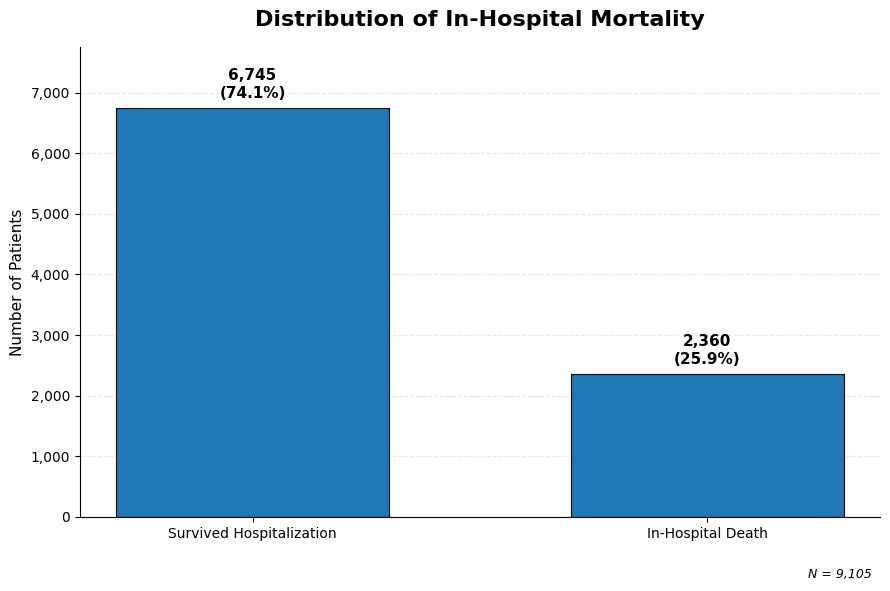

In [13]:
# Prepare mortality counts and percentages
mortality_counts = (
    df["hospdead"]
    .value_counts()
    .sort_index())

mortality_percent = mortality_counts / mortality_counts.sum() * 100

mortality_plot = pd.DataFrame({
    "Outcome": ["Survived Hospitalization", "In-Hospital Death"],
    "Count": mortality_counts.values,
    "Percent": mortality_percent.values})

# Create figure
fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.bar(
    mortality_plot["Outcome"],
    mortality_plot["Count"],
    width=0.6,
    edgecolor="black",
    linewidth=0.8)

# Add count and percentage labels above each bar
for bar, count, pct in zip(
    bars,
    mortality_plot["Count"],
    mortality_plot["Percent"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 120,
        f"{count:,}\n({pct:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold")

# Titles and labels
ax.set_title(
    "Distribution of In-Hospital Mortality",
    fontsize=16,
    fontweight="bold",
    pad=15)

ax.set_xlabel("")
ax.set_ylabel("Number of Patients", fontsize=11)

# Format y-axis with commas
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{int(x):,}"))

# Give labels room above bars
ax.set_ylim(0, mortality_plot["Count"].max() * 1.15)

# Clean up chart appearance
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3)

ax.set_axisbelow(True)

# Add sample-size note
ax.text(
    0.99,
    -0.13,
    f"N = {len(df):,}",
    transform=ax.transAxes,
    ha="right",
    fontsize=9,
    style="italic")

plt.tight_layout()
plt.show()

The visualization demonstrates an imbalance in the binary outcome, with 74.1% of patients surviving hospitalization and 25.9% experiencing in-hospital mortality. Although both outcome classes contain a substantial number of observations, the unequal class distribution suggests that model performance should not be evaluated using accuracy alone. Metrics that account for classification performance across the outcome classes will be considered during model evaluation.

#### Visualization 2: In-Hospital Mortality Rate by Disease Class

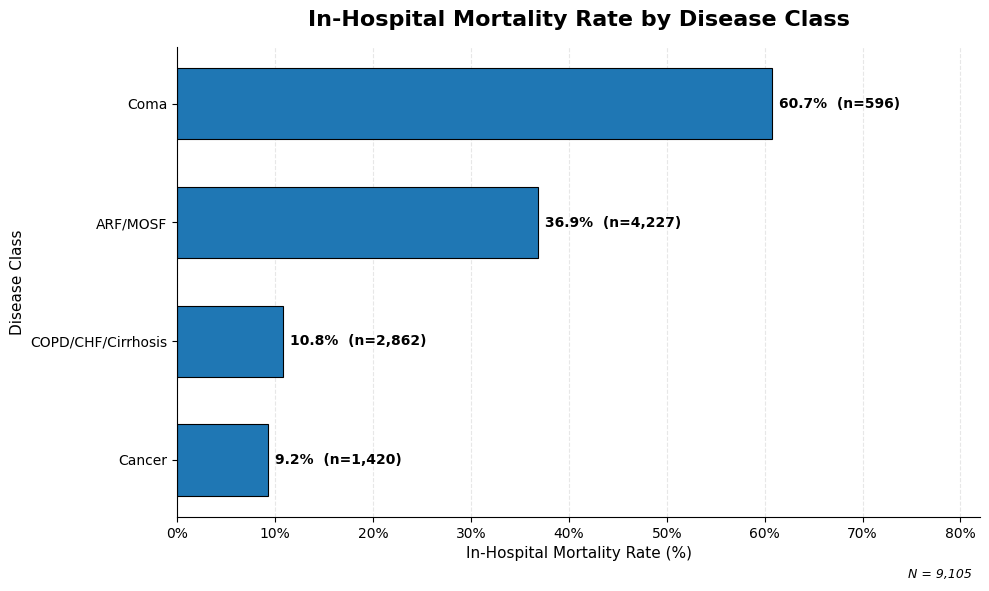

In [14]:
# Calculate mortality rate and sample size by disease class
disease_mortality = (
    df.groupby("dzclass", observed=True)
      .agg(
          mortality_rate=("hospdead", "mean"),
          patient_count=("hospdead", "size")).reset_index())

# Convert mortality rate to percentage
disease_mortality["mortality_percent"] = (
    disease_mortality["mortality_rate"] * 100)

# Sort from highest to lowest mortality rate
disease_mortality = disease_mortality.sort_values(
    "mortality_percent",
    ascending=True)

# Create figure
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    disease_mortality["dzclass"],
    disease_mortality["mortality_percent"],
    height=0.6,
    edgecolor="black",
    linewidth=0.8)

# Add mortality percentage and sample size to each bar
for bar, pct, n in zip(
    bars,
    disease_mortality["mortality_percent"],
    disease_mortality["patient_count"]):
    ax.text(
        bar.get_width() + 0.7,
        bar.get_y() + bar.get_height() / 2,
        f"{pct:.1f}%  (n={n:,})",
        va="center",
        fontsize=10,
        fontweight="bold")

# Titles and labels
ax.set_title(
    "In-Hospital Mortality Rate by Disease Class",
    fontsize=16,
    fontweight="bold",
    pad=15)

ax.set_xlabel("In-Hospital Mortality Rate (%)", fontsize=11)
ax.set_ylabel("Disease Class", fontsize=11)

# Format x-axis as percentages
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:.0f}%"))

# Give labels room
ax.set_xlim(
    0,
    disease_mortality["mortality_percent"].max() * 1.35)

# Clean appearance
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3)

ax.set_axisbelow(True)

# Add overall sample size
ax.text(
    0.99,
    -0.13,
    f"N = {len(df):,}",
    transform=ax.transAxes,
    ha="right",
    fontsize=9,
    style="italic")

plt.tight_layout()
plt.show()

In-hospital mortality varied substantially across disease classes. Patients in the Coma disease class had the highest observed mortality rate at 60.7%, followed by patients in the ARF/MOSF class at 36.9%. Lower mortality rates were observed among patients classified with COPD/CHF/Cirrhosis (10.8%) and Cancer (9.2%). These descriptive differences suggest that disease class may contain useful information for predicting in-hospital mortality. However, these unadjusted rates do not account for differences in patient characteristics, disease severity, or other clinical factors across disease classes.

#### Visualization 3: APACHE III Physiology Score by Outcome

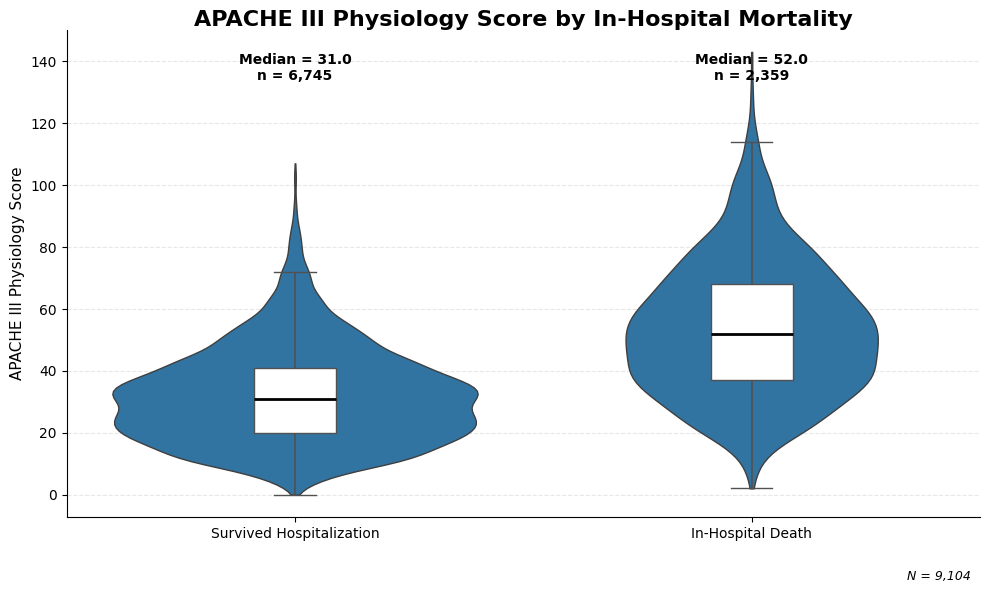

In [15]:
# Prepare data for visualization
aps_plot = df[["aps", "hospdead"]].dropna().copy()

# Replace numeric outcome labels with descriptive labels
aps_plot["Outcome"] = aps_plot["hospdead"].map({
    0: "Survived Hospitalization",
    1: "In-Hospital Death"})

# Create figure
fig, ax = plt.subplots(figsize=(10, 6))

# Violin plot showing the full distribution
sns.violinplot(
    data=aps_plot,
    x="Outcome",
    y="aps",
    inner=None,
    cut=0,
    linewidth=1,
    ax=ax)

# Overlay a compact boxplot
sns.boxplot(
    data=aps_plot,
    x="Outcome",
    y="aps",
    width=0.18,
    showfliers=False,
    boxprops={"facecolor": "white"},
    medianprops={"color": "black", "linewidth": 2},
    whiskerprops={"linewidth": 1.2},
    ax=ax)

# Calculate group medians for annotation
aps_summary = (
    aps_plot.groupby("Outcome")["aps"]
    .agg(["median", "count"])
    .reindex(["Survived Hospitalization", "In-Hospital Death"]))

# Add median and sample-size annotations
for i, (outcome, row) in enumerate(aps_summary.iterrows()):
    ax.text(
        i,
        ax.get_ylim()[1] * 0.95,
        f"Median = {row['median']:.1f}\nn = {int(row['count']):,}",
        ha="center",
        va="top",
        fontsize=10,
        fontweight="bold")

# Titles and labels
ax.set_title(
    "APACHE III Physiology Score by In-Hospital Mortality",
    fontsize=16,
    fontweight="bold",
    pad=1)

ax.set_xlabel("")
ax.set_ylabel("APACHE III Physiology Score", fontsize=11)

# Clean appearance
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3)

ax.set_axisbelow(True)

# Overall sample-size note
ax.text(
    0.99,
    -0.13,
    f"N = {len(aps_plot):,}",
    transform=ax.transAxes,
    ha="right",
    fontsize=9,
    style="italic")

plt.tight_layout()
plt.show()

Patients who experienced in-hospital mortality had substantially higher APACHE III physiology scores than patients who survived hospitalization. The median score was 52 among patients who died compared with 31 among patients who survived. Although the distributions overlap, the distribution for patients who died is shifted toward higher physiology scores, suggesting that greater physiologic severity may be associated with in-hospital mortality in this sample. One observation with a missing APACHE III score was excluded from this visualization.

## Data Quality Assessment

### Missing Values

In [16]:
# Calculate missing values for each variable
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percent": (df.isnull().sum() / len(df)) * 100})

# Keep only variables containing missing values
missing_summary = (
    missing_summary[missing_summary["Missing Count"] > 0]
    .sort_values("Missing Percent", ascending=False))

missing_summary.round(2)

,Missing Count,Missing Percent
adlp,5641,61.95
urine,4862,53.40
glucose,4500,49.42
bun,4352,47.80
totmcst,3475,38.17
alb,3372,37.03
income,2982,32.75
adls,2867,31.49
bili,2601,28.57
pafi,2325,25.54


Missing data are present across several predictor variables, with substantial variation in the amount of missingness. The greatest missingness occurs in `adlp` (61.95%), `urine` (53.40%), `glucose` (49.42%), and `bun` (47.80%). Several additional variables, including `totmcst`, `alb`, `income`, `adls`, `bili`, `pafi`, and `ph`, are missing in more than 25% of observations. In contrast, several clinical variables contain only one or a small number of missing observations. The target variable, `hospdead`, contains no missing values.

Because missingness is substantial for some predictors, simply removing all observations with incomplete data could result in considerable loss of information. The extent and pattern of missingness will therefore need to be considered when determining appropriate preprocessing strategies.

### Potentially Improper or Unusual Observations

In [17]:
# Examine zero and negative values in selected clinical variables
clinical_vars = [
    "meanbp", "wblc", "hrt", "resp",
    "temp", "pafi", "alb", "bili",
    "crea", "sod", "ph", "glucose",
    "bun", "urine"]

quality_check = pd.DataFrame({
    "Minimum": df[clinical_vars].min(),
    "Maximum": df[clinical_vars].max(),
    "Zero Count": (df[clinical_vars] == 0).sum(),
    "Negative Count": (df[clinical_vars] < 0).sum()})

quality_check

,Minimum,Maximum,Zero Count,Negative Count
meanbp,0.000000,195.000000,51,0
wblc,0.000000,200.000000,10,0
hrt,0.000000,300.000000,83,0
resp,0.000000,90.000000,65,0
temp,31.699220,41.695310,0,0
pafi,12.000000,890.375000,0,0
alb,0.399963,29.000000,0,0
bili,0.099991,63.000000,0,0
crea,0.099991,21.500000,0,0
sod,110.000000,181.000000,0,0


Several clinical variables contain zero or extreme values that warrant further investigation before modeling. Zero values were observed for mean arterial blood pressure (`meanbp`), white blood cell count (`wblc`), heart rate (`hrt`), respiratory rate (`resp`), glucose, and urine output. Some variables also contain extreme values, including a maximum glucose value of 1,092, white blood cell count of 200, heart rate of 300, and albumin value of 29.

These observations will not automatically be treated as errors because extreme clinical measurements may occur among seriously ill hospitalized patients, and some zero values may have specific meanings within the original dataset. Variable documentation and distributions should be reviewed before determining whether values represent valid measurements, coding conventions, or improperly coded observations. Any values determined to represent missing or invalid measurements would be recoded appropriately during preprocessing.

### Anticipated Preprocessing

Several preprocessing steps will be necessary before developing the supervised machine learning models. Missing data will be one of the primary preprocessing considerations because the amount of missingness varies substantially across predictors. Rather than applying the same strategy to every variable, the approach will depend on the amount of missingness and the type of variable.

For numerical predictors with relatively low levels of missingness, such as creatinine, white blood cell count, or hospital charges, median imputation may provide a reasonable initial approach because it is less sensitive to extreme values than mean imputation. For variables with moderate missingness, imputation could incorporate information from other observed patient characteristics. For example, missing laboratory or physiologic measurements could potentially be estimated using multivariable approaches that incorporate age, disease class, comorbidities, disease severity measures, and other available clinical variables rather than relying on a single variable such as age. Methods such as iterative or multiple imputation could therefore be compared with simpler median imputation.

Variables with very high levels of missingness will require additional consideration. For example, `adlp` is missing in approximately 62% of observations, while `urine`, `glucose`, and `bun` are missing in approximately 48–53%. Imputing such a large proportion of a variable may introduce substantial uncertainty. These predictors may therefore be evaluated both with and without inclusion in the model rather than automatically imputing all missing observations. Missingness indicators could also be considered for selected variables if the absence of a measurement itself may contain clinically relevant information.

Categorical predictors will require separate preprocessing. Missing categorical values may be represented using an explicit "Missing" or "Unknown" category when appropriate rather than assuming membership in the most common category. Categorical variables such as sex, disease group, disease class, income, race, cancer status, and DNR status will then need to be encoded for machine learning, potentially using one-hot encoding. Variables will be classified according to their documented meaning rather than pandas data type alone because some predictors are stored numerically despite representing categorical, ordinal, or binary information.

Potentially unusual clinical values identified during data quality assessment will also be reviewed before modeling. Zero values in variables such as heart rate, respiratory rate, mean arterial blood pressure, glucose, and white blood cell count will be compared with the dataset documentation and variable distributions to determine whether they represent valid clinical measurements, coding conventions, or missing/invalid observations. Extreme values will not automatically be removed because the SUPPORT2 population consists of seriously ill hospitalized patients, in whom extreme physiologic and laboratory measurements may be clinically plausible.

Continuous variables may be standardized for models that are sensitive to predictor scale, such as logistic regression. Highly skewed variables, including hospital charges and costs, may also be evaluated for transformations if their distributions could negatively affect model performance. Tree-based models may require less scaling or transformation, so preprocessing choices may differ by model.

Finally, all imputation, encoding, scaling, and other learned preprocessing transformations will be incorporated into the modeling pipeline and fit using the training data only. The dataset will be separated into training and testing sets before these transformations are learned so that information from the test set does not influence preprocessing decisions. This approach will reduce the risk of data leakage and provide a more realistic estimate of model performance.

**Research Context:** The approach to missing-data preprocessing in this project is also informed by my graduate capstone research. My capstone examines how different missing-data preprocessing strategies affect logistic regression models for ICU mortality prediction using MIMIC-IV data. The planned capstone analysis compares complete-case analysis, median imputation, median imputation with missingness indicators, and multiple imputation, with model performance evaluated using measures of discrimination and calibration.

Because missing-data methodology is a central component of my capstone, I am particularly interested in treating missingness in the SUPPORT2 dataset as an analytical consideration rather than simply applying an automated machine-learning imputation method. For this project, I plan to use clinically and statistically interpretable approaches, such as median imputation for variables with limited missingness and multivariable imputation strategies that use observed patient characteristics such as age, disease characteristics, comorbidities, and severity measures when appropriate. This provides an opportunity to apply concepts related to missing-data handling in a second clinical dataset while considering how preprocessing decisions may influence mortality prediction.

### Potential Dataset Challenges

Several challenges associated with the SUPPORT2 dataset may affect model development and interpretation.

One of the primary challenges is the extent and variability of missing data. Missingness ranges from only a few observations for some predictors to more than half of the observations for variables such as `adlp` and `urine`. This creates a tradeoff between retaining potentially useful clinical information and introducing uncertainty through extensive imputation. Additionally, missing clinical measurements may not occur randomly. For example, whether a laboratory test or assessment was obtained may be related to a patient's condition or clinical care. Therefore, the potential informativeness of missingness should be considered when selecting an imputation strategy.

A second challenge is the presence of unusual or extreme clinical observations. Several physiologic and laboratory variables contain zero or very high values that require validation before modeling. Because the study population consists of seriously ill hospitalized patients, extreme measurements cannot automatically be assumed to be errors. Distinguishing clinically plausible values from coding conventions or invalid measurements will require careful consideration of the variable documentation and observed distributions.

The dataset also contains a mixture of continuous, categorical, ordinal, and binary predictors. Some variables are stored numerically even though their documented meaning may be categorical or ordinal. Consequently, relying only on pandas data types could result in inappropriate preprocessing. Predictor types will need to be defined based on both their statistical representation and clinical meaning before encoding, scaling, or imputation.

Another potential challenge is the relationship between certain predictors and the timing of the prediction outcome. Variables such as survival estimates, DNR information, hospital charges, costs, and other hospitalization-related measures may contain information that was generated during the patient's hospitalization. Before modeling, these variables will need to be reviewed to determine when they became available relative to the intended prediction point. Predictors containing information that would not realistically be available when a mortality prediction is intended to occur could introduce data leakage or make model performance appear stronger than it would be in prospective use.

The outcome also demonstrates moderate class imbalance. Approximately 25.9% of patients experienced in-hospital mortality compared with 74.1% who survived hospitalization. Although the minority class contains a substantial number of observations, accuracy alone could provide a misleading assessment of model performance. Evaluation should therefore include metrics that assess discrimination and performance for the mortality outcome rather than relying exclusively on overall accuracy.

Finally, model interpretation will require caution because this is an observational clinical dataset. Relationships identified between predictors and in-hospital mortality should be interpreted as predictive associations rather than evidence that individual variables cause mortality. Differences in underlying disease, severity, treatment, and other patient characteristics may contribute to observed relationships.

## Project Planning

### Proposed Prediction Problem

The proposed prediction problem is to determine whether demographic, disease-related, physiologic, laboratory, and other clinical characteristics can be used to predict in-hospital mortality among seriously ill hospitalized patients in the SUPPORT2 dataset. This will be approached as a supervised binary classification problem in which patient-level characteristics are used to estimate the probability that a patient will die during the hospitalization.

The intended prediction point will be defined carefully before model development because several SUPPORT2 variables are collected during hospitalization. Predictors will be reviewed for their timing and clinical availability so that variables containing information that would not realistically be available at the intended prediction point do not introduce data leakage. The goal of the model is therefore not simply to maximize predictive performance, but to evaluate whether clinically available patient information can provide useful discrimination of in-hospital mortality risk.

### Target Variable

The target variable will be `hospdead`, which represents in-hospital mortality and is appropriate for binary classification:

- `0` = patient survived hospitalization
- `1` = patient died during hospitalization

The dataset contains 6,745 patients (74.1%) in the negative class and 2,360 patients (25.9%) in the positive class. Because the positive mortality class represents approximately one-quarter of the sample, evaluation metrics will be selected with this class imbalance in mind.

### Candidate Evaluation Metrics

The primary candidate evaluation metric will be the **Area Under the Receiver Operating Characteristic Curve (ROC-AUC)**. ROC-AUC evaluates how well a model discriminates between patients who experience in-hospital mortality and those who survive across possible classification thresholds. It is preferable to accuracy as the primary metric because approximately 74% of patients survived hospitalization, meaning that overall accuracy could appear relatively high even for a model that performs poorly at identifying patients who die.

Additional evaluation metrics will be considered to provide a more complete assessment of model performance. **Precision-recall AUC (PR-AUC)** may be particularly informative because in-hospital mortality is the less common outcome and represents the positive class. **Sensitivity (recall)** will also be examined because it measures the proportion of patients who experienced in-hospital mortality who were correctly identified by the model. Specificity and precision may be reported alongside sensitivity to examine the tradeoff between identifying mortality cases and incorrectly classifying survivors as high risk.

Because the models may ultimately produce predicted probabilities of mortality rather than only binary classifications, **calibration** will also be evaluated. A model may successfully rank patients by relative risk while still producing probabilities that do not correspond well to observed mortality. Calibration plots and potentially the Brier score can therefore complement discrimination metrics such as ROC-AUC and PR-AUC.

ROC-AUC will serve as the primary candidate metric for comparing model discrimination, while PR-AUC, sensitivity, specificity, precision, and calibration measures will provide complementary information about clinical prediction performance.